# ****BUSINESS UNDERSTANDING****

<p align="center">
    <img src="../xLain-Lain/img/bu_2.png" alt="Pendahuluan" witdh="100" height="500">
</p>

### ****DAFTAR ISI****

1. Tujuan dan Posisi Notebook dalam Alur CRISP-DM
2. Latar Belakang dan Konteks Bisnis
3. Perumusan Masalah
4. Tujuan Bisnis -> Tujuan Data Mining
5. Kriteria Keberhasilan
6. Landasan Teori dan Hipotesis Ekonomi
7. Analisis Situasi: Sumber Daya, Asumsi, Batasan, dan Risiko
8. Skema Prediksi dan Prinsip Anti-Leakage
9. Rencana Proyek dan Jadwal
10. Konfigurasi Proyek dan Uji Kesiapan
11. Kesimpulan dan Langkah Berikutnya
12. Referensi

---

### ****1. Tujuan dan Posisi Notebook dalam Alur CRISP-DM****

CRISP-DM (Chapman et al., 2000) adalah kerangka proses data mining yang bersifat iteratif: hasil di satu fase dapat mengembalikan pekerjaan ke fase sebelumnya. Kerangka ini dipilih karena: menjadi standar de facto lintas industri; memaksa pemisahan yang tegas antara memahami masalah, memahami data, dan membangun model; selaras dengan struktur folder proyek tim.

Tujuan notebook ini:

1. Menerjemahkan narasi studi kasus menjadi **masalah prediksi yang terdefinisi secara formal**.
2. Menetapkan **kriteria keberhasilan yang terukur** sebelum melihat hasil model.
3. Merumuskan **hipotesis ekonomi yang dapat diuji** sebagai dasar rekayasa fitur (Task 1).
4. Mengidentifikasi **risiko** utama beserta mitigasinya, terutama risiko kebocoran data (Task 2) dan pergeseran rezim pasar (Task 3).
5. Menyusun rencana kerja yang realistis terhadap tenggat.

Gambar di bawah ini menggambarkan peta jalan proyek.

<p align="center">
    <img src="../xLain-Lain/img/bu_4.png" alt="Pendahuluan" witdh="100" height="400">
</p>

*Fase *Deployment* pada CRISP-DM standar tidak dilakukan secara nyata (di luar lingkup lomba), tetapi kami mengisinya dengan cetak biru Sistem Peringatan Dini dan rekomendasi bagi manajemen risiko.*

### ****2. Latar Belakang dan Konteks Bisnis****

**PT Investion** adalah pengelola aset dengan dana kelolaan bernilai triliunan rupiah yang sangat terpapar pada pergerakan Indeks Harga Saham Gabungan (IHSG). Studi kasus menyebut empat saluran transmisi guncangan eksternal ke pasar saham domestik:

| Saluran | Variabel pada Dataset | Mekanisme Ekonomi |
|---|---|---|
| Sentimen risiko global | `VIX`, `SP500` | Lonjakan ketakutan investor global memicu penarikan dana dari pasar negara berkembang (*risk-off*) |
| Kurs | `USDIDR` | Depresiasi rupiah menggerus imbal hasil investor asing dalam mata uang dasar dan memicu *capital outflow* |
| Komoditas | `OIL`, `GOLD` | Minyak mencerminkan siklus ekonomi dan biaya input; emas berfungsi sebagai aset *safe haven* |
| Kebijakan moneter | `BI_rate`, `US_rate`, `CPI` | Selisih suku bunga menentukan daya tarik aset rupiah; inflasi memengaruhi ekspektasi kebijakan |

Guncangan tersebut tidak berdampak sesaat. Pasar keuangan menunjukkan *Volatility Clustering*, yakni periode bergejolak cenderung diikuti periode bergejolak lain (Mandelbrot, 1963; Engle, 1982). Akibatnya, pengelolaan risiko yang hanya mengandalkan tren harga historis kurang memadai: arah harga sulit diprediksi, tetapi besarnya gejolak jauh lebih dapat diprediksi karena persistensinya (Bollerslev, 1986; Corsi, 2009).

<table>
  <tr>
    <td><img src="../xLain-Lain/img/bu_5.png" width="400" alt="Mandelbrot"></td>
  </tr>
</table>

Dua tuntutan yang membedakan proyek ini dari proyek prediksi biasa:

1. Peringatan dini, bukan sekedar prakiraan. Nilai bisnisnya ada pada kemampuan sinyal sebelum gejolak terjadi.
2. Tanpa *black box*. Komite risiko menuntut pertanggungjawaban logis atas setiap prediksi, sehingga model harus dapat dibongkar dengan XAI.

### ****3. Perumusan Masalah (Formal)****

**Pertanyaan Bisnis**. *Seberapa bergejolak IHSG dalam 5 hari perdagangan ke depan dan faktor ekonomi apa yang menjelaskan prediksi tersebut?*

**Formalisasi**. Misalkan $P_t$ adalah harga penutupan IHSG pada hari perdagangan $t$ dan $r_t = P_t/P_{t-1} - 1$ adalah *return* hariannya. Misalkan $\mathcal{F}_t$ adalah seluruh informasi yang tersedia setelah penutupan hari $t$. Hipotesis kerja untuk target adalah

$$
Y_t \;=\; \sigma_{t,\,t+5} \;=\; \sqrt{\frac{1}{4}\sum_{i=1}^{5}\left(r_{t+i}-\bar r_{t,5}\right)^2},\qquad \bar r_{t,5}=\frac{1}{5}\sum_{i=1}^{5} r_{t+i}.
$$

Tugas pemodelan adalah mempelajari fungsi

$$
\hat Y_t = f\big(\mathbf{x}_t\big),\qquad \mathbf{x}_t \in \mathcal{F}_t,
$$

yang meminimalkan galat prediksi (RMSE/MAE, serta QLIKE sebagai pelengkap) di bawah kendala kausalitas: $\mathbf{x}_t$ tidak boleh memuat informasi apa pun yang baru diketahui pada $t+1$ atau sesudahnya.

**Catatan penting.** Karena $Y_t$ sendiri dibangun dari *return* masa depan ($t+1,\dots,t+5$), kebocoran data dapat terjadi secara halus, misalnya lewat *lag* target yang masih tumpang tindih dengan jendela masa depan. Hal ini dianalisis tuntas di Notebook 2 dan diatasi di Notebook 3.

**Jenis masalah:** regresi deret waktu univariat-target dengan prediktor multivariat eksogen dan horizon tetap $h=5$ hari. **Unit observasi:** satu hari perdagangan. **Data uji:** seluruh baris sejak 2025 (nilai $Y$ tidak tersedia).

### ****4. Tujuan Bisnis -> Tujuan Data Mining****

| # | Tujuan Bisnis (PT Investion) | Tujuan Data Mining yang Menerjemahkannya | Bukti yang akan Ditampilkan |
|---|---|---|---|
| BO1 | Mendapat indikasi dini kondisi pasar berisiko | *DM1*: model regresi $\hat Y_t$ untuk volatilitas 5 hari ke depan<br>*DM2*: konversi $\hat Y_t$ ke level peringatan Hijau/Kuning/Merah berbasis kuantil data latih | RMSE/MAE/QLIKE vs. baseline; presisi-*recall* kejadian volatilitas tinggi |
| BO2 | Setiap prediksi dapat dipertanggungjawabkan | *DM3:* XAI global (SHAP summary), lokal (*waterfall*), dan analisis kesalahan berbasis XAI | Grafik SHAP; narasi bisnis tiap fitur |
| BO3 | Sistem dapat dipercaya (tanpa informasi "dari masa depan") | *DM4:* pemisahan *walk-forward* dengan *purge gap*, *pipeline* yang di-*fit* hanya pada data latih, dan uji kausalitas fitur | Uji pemotongan data (*truncation test*) lulus 100% |
| BO4 | Sistem tetap andal saat rezim pasar berubah (2025–2026) | *DM5:* fitur stasioner, analisis *drift* latih vs uji, evaluasi pada fold bertekanan | Uji ADF/KPSS, *adversarial validation*, kinerja per rezim |

### ****5. Kriteria Keberhasilan****

Kenapa kami tetapkan kriteria sebelum pemodelan? Agar penilaian tidak dibelokkan oleh hasil yang kebetulan baik.

**A. Kriteria Teknis (kuantitatif)**

| # | Kriteria | Ukuran |
|---|---|---|
| T1 | Model ML lebih akurat daripada baseline naif (rata-rata volatilitas 5 hari ke belakang) | RMSE dan MAE lebih kecil pada validasi *walk-forward*, secara konsisten di mayoritas fold |
| T2 | Keunggulan bersifat signifikan secara statistik | Uji Diebold-Mariano (1995) dengan $p<0{,}05$ pada galat kuadrat/absolut |
| T3 | Model bersaing dengan *benchmark* ekonometrik standar | Dibandingkan dengan HAR-OLS (Corsi, 2009) dan GARCH(1,1) (Bollerslev, 1986); aspirasi: setara atau lebih baik |
| T4 | Tidak ada kebocoran data | Uji kausalitas: fitur pada hari $t$ identik bila data setelah $t$ dihapus; fit *scaler/imputer* hanya pada data latih |
| T5 | Tuning bersih | Seluruh pencarian hyperparameter hanya memakai data latih dan validasi |
| T6 | Penjelasan stabil | Peringkat fitur SHAP konsisten antar fold dan sejalan dengan *permutation importance* |

**B. Kriteria Bisnis (kualitatif)**

| # | Kriteria |
|---|---|
| B1 | Setiap fitur utama memiliki logika ekonomi eksplisit yang dapat dijelaskan kepada komite risiko |
| B2 | Penjelasan lokal dapat diterjemahkan ke bahasa bisnis untuk tanggal berisiko tinggi |
| B3 | Kelemahan model (kapan ia meleset dan mengapa) diungkapkan secara jujur |

**C. Kriteria Kompetisi**

| # | Kriteria |
|---|---|
| K1 | Notebook `DSC_apa ya namanya, bingung juga_Notebook.ipynb` menjawab seluruh Task 1–3 |
| K2 | Slide `DSC_apa ya namanya, bingung juga_PPT.pptx` berbahasa Indonesia, tanpa unsur terlarang |
| K3 | Kode orisinal; tautan Drive diunggah sebelum 29 Oktober 2026 pukul 23.59 WIB |

*Kami sengaja tidak menetapkan target angka RMSE absolut. Tingkat kesulitan prediksi volatilitas bergantung pada rezim pasar, sehingga angka absolut tanpa konteks mudah menyesatkan. Ukuran yang bermakna adalah perbaikan relatif terhadap baseline pada protokol validasi yang sama*


### ****6. Landasan Teori dan Hipotesis Ekonomi****

**6.1 Volatilitas Sebagai Besaran yang Dapat Diprediksi**

Harga aset hampir tidak dapat diprediksi arahnya, tetapi kuadrat atau nilai mutlak return menunjukkan autokorelasi positif yang kuat dan bertahan lama. Inilah dasar keluarga model ARCH/GARCH (Engle, 1982; Bollerslev, 1986). Hansen & Lunde (2005) menunjukkan bahwa GARCH(1,1) sangat sulit dikalahkan secara konsisten, sehingga ia menjadi benchmark yang adil.

**6.2 Struktur Multi-Horizon (HAR)**

Model HAR-RV (Corsi, 2009) menjelaskan volatilitas ke depan sebagai kombinasi linear volatilitas realisasi harian, mingguan, dan bulanan, yang mencerminkan perilaku pelaku pasar dengan horizon investasi berbeda. Komponen volatilitas jangka pendek dan menengah dari IHSG hampir pasti menjadi prediktor penting, sehingga fitur kami harus memberi informasi di luar apa yang sudah ditangkap komponen tersebut.

**6.3 Leverage Effect**

Guncangan negatif cenderung menaikkan volatilitas lebih besar daripada guncangan positif berukuran sama (Black, 1976; Engle & Ng, 1993). Implikasinya, ukuran volatilitas turun (*downside semivariance*) layak diuji sebagai fitur.

**6.4 Transmisi Lintas Pasar**

- Ketakutan Global. VIX adalah ukuran volatilitas implisit S&P 500 yang dikenal sebagai *investor fear gauge* (Whaley, 2000). Selisih antara ekspektasi volatilitas (implisit) dan volatilitas yang terealisasi dikenal sebagai *variance risk premium* dan memiliki kekuatan prediktif atas pergerakan pasar (Bollerslev, Tauchen & Zhou, 2009).
- Siklus Keuangan Global. Rey (2013) menunjukkan bahwa siklus keuangan global (tercermin pada VIX dan kebijakan moneter AS) memengaruhi kondisi keuangan negara berkembang terlepas dari rezim kurs mereka. Forbes & Warnock (2012) mendokumentasikan gelombang arus modal ke negara berkembang yang dipicu faktor global.
- Emas berfungsi sebagai *safe haven* saat pasar tertekan (Baur & Lucey, 2010); Minyak adalah penanda siklus ekonomi dan guncangan permintaan/penawaran (Hamilton, 2009).

**6.5 Daftar Hipotesis yang Akan Diuji**

Hipotesis berikut menjadi dasar kandidat fitur pada Task 1. Tiga fitur terbaik dipilih berdasarkan bukti EDA dan validasi.


| ID | Kandidat Fitur | Mekanisme Ekonomi | Tanda Diharapkan | Bukti yang Diminta |
| :--- | :--- | :--- | :---: | :--- |
| H1 | Variance Risk Premium proxy<br>*(VIX terskala - RV IHSG)* | Ketakutan global yang belum terserap pasar domestik akan menyusul sebagai lonjakan volatilitas IHSG | + | Korelasi Spearman, SHAP dependence |
| H2 | Rupiah Stress Index<br>*(z-score return USDIDR x spread BI-US)* | Depresiasi rupiah + selisih bunga menyempit memicu arus modal keluar, menaikkan volatilitas ekuitas | + | Korelasi, importance, SHAP lokal |
| H3 | Rasio volatilitas jangka pendek/menengah<br>*(RV5 / RV22)* | Volatilitas melonjak jauh di atas rata-rata bulanan cenderung kembali ke rata-rata (*mean reversion*) | +/- | Korelasi, SHAP dependence non-linear |
| H4 | Downside semivariance IHSG | Guncangan negatif menaikkan volatilitas lebih besar daripada guncangan positif (*leverage effect*) | + | Perbandingan dengan RV simetris |
| H5 | Guncangan emas dan minyak<br>*( \|return\|, z-score)* | Gejolak komoditas menandakan perubahan sentimen/permintaan dan perpindahan ke *safe haven* | + | Korelasi, importance |
| H6 | Perubahan VIX 1 dan 5 hari | Percepatan ketakutan global lebih informatif daripada levelnya | + | Korelasi, SHAP | NB3, NB5 |
| H7 | Hari sejak perubahan suku bunga BI / The Fed | Guncangan kebijakan menimbulkan ketidakpastian sementara yang meluruh seiring waktu | - | Dependence plot |

### ****7. Analisis Situasi: Sumber Daya, Asumsi, Batasan, dan Risiko****

**7.1 Sumber Daya**

| Kategori | Rincian |
|---|---|
| Data | 4.266 baris harian (2010-01-04 s.d. 2026-05-22), 11 kolom; $Y$ tersedia untuk 2010 - 2024 dan kosong untuk 2025 - 2026 |

**7.2 Asumsi**

1. Waktu prediksi adalah setelah penutupan hari $t$. Penutupan S&P 500 dan VIX hari $t$ (waktu AS) terjadi sebelum IHSG dibuka pada hari $t+1$, sehingga keduanya sah dipakai sebagai prediktor.
2. Setiap baris pada dataset merepresentasikan satu hari kerja. Nilai yang tidak berubah pada hari libur (*stale price*) dianggap hasil *forward-fill*.
3. Kolom makroekonomi (CPI, BI_rate, US_rate) adalah seri berfrekuensi rendah yang diperbarui secara berkala.

**7.3 Batasan**

- Data uji tidak memiliki label sehingga kinerja pada 2025–2026 tidak dapat diukur secara langsung. Evaluasi bertumpu pada validasi *walk-forward* di data berlabel.
- Hanya satu model utama yang boleh dipilih. *Benchmark* dan kandidat seleksi diperbolehkan sebagai pembanding :(

**7.4 Risiko**


| # | Risiko | Dampak | Mitigasi |
|---|---|---|---|
| R1 | Kebocoran lewat lag target (mis. $Y_{t-1}$ memuat *return* $t+1\ldots t+4$) | Kinerja tampak sangat baik padahal tidak | Hanya *lag* $Y_{t-5}$ ke belakang yang boleh dipakai; uji kausalitas otomatis |
| R2 | Label tumpang tindih membuat validasi bocor di batas *train/validation* | Estimasi galat terlalu optimistis | *Purge gap* ≥ 5 hari pada seluruh pemisahan |
| R3 | Pergeseran rezim 2025 - 2026 (volatilitas dan level variabel di luar rentang latih) | Model gagal pada data uji | Fitur stasioner (return, rasio, z-score), bukan level; *adversarial validation*; fold bertekanan |
| R4 | Validasi 2023 - 2024 terlalu tenang | Kelemahan model pada krisis tidak terlihat | *Walk-forward* yang mencakup 2018, 2020, dan 2022 |
| R5 | Anomali data (salah desimal, harga minyak negatif, *stale price*) | Fitur *return* meledak, bias ke bawah pada volatilitas | Audit dan Koreksi |
| R6 | *Overfitting* saat tuning | Kinerja validasi palsu | Pencarian terbatas, CV *walk-forward*, laporan *nested* jika waktu mengizinkan |
| R7 | Salah tafsir SHAP sebagai kausalitas | Narasi bisnis menyesatkan | Bahasa "kontribusi terhadap prediksi", bukan "penyebab"; triangulasi dengan *permutation importance* |
| R8 | Seri makro frekuensi rendah dapat memuat informasi yang baru diumumkan setelah tanggal tercatat | Kebocoran halus | Uji sensitivitas dengan *lag* publikasi |

### ****8. Skema Prediksi dan Prinsip Anti-Leakage****

<p align="center">
    <img src="../xLain-Lain/img/bu_6.png" alt="Pendahuluan" witdh="100" height="500">
</p>


- Panel atas, set informasi. Pada hari $t$, hanya data sampai penutupan $t$ yang boleh dipakai sebagai fitur. Target $Y_t$ dihitung dari *return* hari $t+1$ s.d. $t+5$. Akibatnya, $Y_{t-5}$ (yang memakai *return* hingga hari $t$) boleh dipakai sebagai fitur, tetapi $Y_{t-4},\ldots,Y_{t-1}$ tidak boleh karena memuat *return* setelah $t$.
- Panel bawah, *purged walk-forward*. Karena label tumpang tindih lima hari, baris latih di ujung blok latih memiliki label yang bergantung pada harga di dalam blok validasi.

**Aturan Anti-Leakage yang Kami Pakai:**

1. Tidak ada pengacakan data.
2. Fitur hari $t$ hanya dihitung dari data sampai $t$ (operasi rolling, shift(k>=0), diff, ewm. Tidak ada shift(-k), tidak ada *centered window*)
3. Satu-satunya *lag* target yang diizinkan adalah $Y_{t-5}$ dan yang lebih lama.
4. *Scaler*, *imputer*, dan *encoder* di-*fit* hanya pada data latih setiap fold, lalu di-*transform* ke validasi dan uji.
5. *Purge gap* ≥ 5 hari antara blok latih dan validasi.
6. Hyperparameter dicari hanya dengan data latih dan validasi. Data uji (2025+) tidak pernah dipakai untuk memilih apa pun.
7. *Truncation test* yang membuktikan poin 2.

### ****9. Rencana Proyek dan Jadwal****

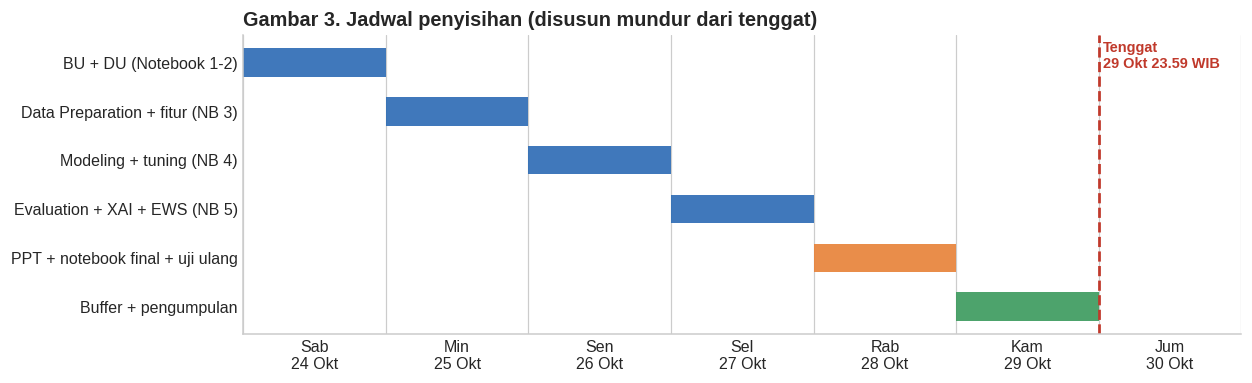

### ****10. Konfigurasi Proyek dan Uji Kesiapan****

In [5]:
import pandas as pd
from pathlib import Path

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, cwd.parent] if (p / "Dataset").exists()), cwd)
RAW_DIR = ROOT / "Dataset" / "Raw"

candidates = [RAW_DIR / "dataset peserta.csv", RAW_DIR / "dataset_peserta.csv"]
DATA_PATH = next((p for p in candidates if p.exists()), None)
assert DATA_PATH is not None, f"Dataset tidak ditemukan. Dicari di: {[str(c) for c in candidates]}"

EXPECTED_COLUMNS = ["Date", "OIL", "GOLD", "USDIDR", "SP500", "IHSG", "VIX", "CPI", "BI_rate", "US_rate", "Target_Volatilitas_Y"]
raw = pd.read_csv(DATA_PATH, parse_dates=["Date"])

checks = {
    "Berkas ditemukan": True,
    "Kolom sesuai": list(raw.columns) == EXPECTED_COLUMNS,
    "Tanggal terurut menaik": raw["Date"].is_monotonic_increasing,
    "Tidak ada tanggal duplikat": not raw["Date"].duplicated().any(),
    "Semua baris adalah hari kerja (Sen-Jum)": bool((raw["Date"].dt.dayofweek < 5).all()),
    "Fitur X bebas missing value": not raw.drop(columns="Target_Volatilitas_Y").isna().any().any(),
    "Y kosong HANYA sejak 2025": bool(raw.loc[raw["Target_Volatilitas_Y"].isna(), "Date"].min() >= pd.Timestamp("2025-01-01")),
}
report = pd.DataFrame({"Pemeriksaan": checks.keys(), "Lulus": ["YA" if v else "TIDAK" for v in checks.values()]})
display(report.style.hide(axis="index"))

n_lab  = raw["Target_Volatilitas_Y"].notna().sum()
n_test = raw["Target_Volatilitas_Y"].isna().sum()
print(f"\nBerkas : {DATA_PATH.relative_to(ROOT)}")
print(f"Dimensi : {raw.shape[0]:,} baris x {raw.shape[1]} kolom")
print(f"Rentang : {raw['Date'].min():%Y-%m-%d} s.d. {raw['Date'].max():%Y-%m-%d}")
print(f"Berlabel : {n_lab:,} baris (2010-2024) | Data uji tanpa label: {n_test:,} baris (2025+)")
assert all(checks.values()), "Gagal."

Pemeriksaan,Lulus
Berkas ditemukan,YA
Kolom sesuai,YA
Tanggal terurut menaik,YA
Tidak ada tanggal duplikat,YA
Semua baris adalah hari kerja (Sen-Jum),YA
Fitur X bebas missing value,YA
Y kosong HANYA sejak 2025,YA



Berkas : Dataset\Raw\dataset_peserta.csv
Dimensi : 4,266 baris x 11 kolom
Rentang : 2010-01-04 s.d. 2026-05-22
Berlabel : 3,907 baris (2010-2024) | Data uji tanpa label: 359 baris (2025+)


### ****11. Kesimpulan dan Langkah Berikutnya****

**Ringkasan keputusan pada tahap Business Understanding**

| # | Keputusan | Dasar |
|---|---|---|
| D1 | Masalah dirumuskan sebagai regresi deret waktu, horizon 5 hari, kausal terhadap $\mathcal{F}_t$ | Studi kasus; Bagian 3 |
| D2 | Keberhasilan diukur sebagai perbaikan relatif atas baseline naif, HAR, dan GARCH, dengan uji Diebold-Mariano | Hansen & Lunde (2005); Diebold & Mariano (1995) |
| D3 | Hanya fitur stasioner (return, rasio, z-score, selisih) yang akan dipakai | Risiko R3 |
| D4 | *Walk-forward* ekspansif dengan *purge gap* 5 hari. Tidak ada pengacakan | López de Prado (2018); Bergmeir & Benítez (2012) |
| D5 | Hanya $Y_{t-5}$ dan yang lebih lama yang boleh menjadi fitur | Resiko R1 |
| D6 | Label 2025+ tidak direkonstruksi untuk pelatihan atau tuning | Batasan 7.3 |
| D7 | Tujuh hipotesis (H1–H7) menjadi sumber kandidat fitur X1–X3 | Bagian 6.5 |

**Pertanyaan yang Akan Dijawab Notebook 2 (Data Understanding) oleh Kami**

1. Bagaimana tepatnya $Y$ dihitung? Apakah hipotesis kerja pada Bagian 3 benar?
2. Seberapa bersih data? Adakah anomali, nilai *stale*, atau kesalahan input?
3. Berapa frekuensi pembaruan sebenarnya dari `CPI`, `BI_rate`, dan `US_rate`?
4. Seperti apa distribusi dan dinamika $Y$ (kemencengan, *clustering*, rezim)?
5. Seberapa jauh data uji 2025–2026 menyimpang dari data latih?
6. Variabel mana yang menjanjikan sebagai sumber fitur, dan apakah variabel tersebut stasioner?

### ****12. Referensi****

- Baur, D. G., & Lucey, B. M. (2010). Is gold a hedge or a safe haven? An analysis of stocks, bonds and gold. *The Financial Review*, 45(2), 217- 229.
- Bergmeir, C., & Benítez, J. M. (2012). On the use of cross-validation for time series predictor evaluation. *Information Sciences*, 191, 192 - 213.
- Black, F. (1976). Studies of stock price volatility changes. *Proceedings of the 1976 Meetings of the American Statistical Association, Business and Economic Statistics Section*, 177–181.
- Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, 31(3), 307 - 327.
- Bollerslev, T., Tauchen, G., & Zhou, H. (2009). Expected stock returns and variance risk premia. *Review of Financial Studies*, 22(11), 4463 - 4492.
- Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS Inc.
- Corsi, F. (2009). A simple approximate long-memory model of realized volatility. *Journal of Financial Econometrics*, 7(2), 174 - 196.
- Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253 - 263.
- Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica*, 50(4), 987 - 1007.
- Engle, R. F., & Ng, V. K. (1993). Measuring and testing the impact of news on volatility. *The Journal of Finance*, 48(5), 1749 - 1778.
- Forbes, K. J., & Warnock, F. E. (2012). Capital flow waves: Surges, stops, flight, and retrenchment. *Journal of International Economics*, 88(2), 235 - 251.
- Hamilton, J. D. (2009). Causes and consequences of the oil shock of 2007–08. *Brookings Papers on Economic Activity*, Spring 2009, 215 - 283.
- Hansen, P. R., & Lunde, A. (2005). A forecast comparison of volatility models: Does anything beat a GARCH(1,1)? *Journal of Applied Econometrics*, 20(7), 873 - 889.
- López de Prado, M. (2018). *Advances in Financial Machine Learning*. Wiley.
- Mandelbrot, B. (1963). The variation of certain speculative prices. *The Journal of Business*, 36(4), 394 - 419.
- Rey, H. (2013). Dilemma not trilemma: The global financial cycle and monetary policy independence. In *Global Dimensions of Unconventional Monetary Policy* (Jackson Hole Economic Policy Symposium), Federal Reserve Bank of Kansas City, 285 - 333.
- Whaley, R. E. (2000). The investor fear gauge. *The Journal of Portfolio Management*, 26(3), 12 - 17.

---